## RQ3: build the modeling dataset

One row per completed flight, with only pre-flight features (PDF section 5, step 1): the flight itself, the RQ1 route cluster and the RQ2 airport communities. RQ1 and RQ2 outputs are read from `results/tables/`, nothing is recomputed here.


# Loading data

In [82]:
import pandas as pd
from pathlib import Path
import sys
import seaborn as sns
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    log_loss, brier_score_loss,
    precision_score, recall_score, f1_score
)

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import CLEAN_PARQUET, TABLES_DIR
from src.data_loading import load_flights

In [69]:
FLIGHTS_SRC = "flights_2024_clean.parquet"

'''
    We define the columns that we want to use, and to make it easier for the next guy to understand, 
    We also added the source for each
'''
BASELINE_COLS = [
    ("route_past_delay_rate", f"I could not find late arrivals, so we make them in this script. But I first add them later because it depends on the split "),
]
EBM_COLS = [  # the flight's own features
    ("month", FLIGHTS_SRC),
    ("day_of_week", FLIGHTS_SRC),
    ("sched_hour", f"{FLIGHTS_SRC}: crs_dep_time // 100"),
    ("op_unique_carrier", FLIGHTS_SRC),
    ("distance", FLIGHTS_SRC),
]
RQ1_COLS = [
    ("route_cluster", "rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier)"),
    ("cluster_past_delay_rate", "rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster)"),
]
RQ2_COLS = [
    ("origin_community", "03_airports.csv: louvain (joined on origin)"),
    ("dest_community", "03_airports.csv: louvain (joined on dest)"),
    ("crosses_community", "derived: origin_community != dest_community"),
    ("origin_betweenness", "03_airports.csv: betweenness (joined on origin)"),
    ("dest_betweenness", "03_airports.csv: betweenness (joined on dest)"),
]
OTHER_COLS = [  # not features: route key for the baseline, and the target
    ("origin", FLIGHTS_SRC),
    ("dest", FLIGHTS_SRC),
    ("late_arrival", f"target, {FLIGHTS_SRC}: arr_delay >= 15"),
]

ROUTE_KEYS = ["origin", "dest", "op_unique_carrier"]

# The above is good for the printing, but when we want to use it,
# this is more convinent
BASELINE_COLS_LIST = [c for c, _ in BASELINE_COLS]
EBM_COLS_LIST = [c for c, _ in EBM_COLS]
RQ1_COLS_LIST = [c for c, _ in RQ1_COLS]
RQ2_COLS_LIST = [c for c, _ in RQ2_COLS]
OTHER_COLS_LIST = [c for c, _ in OTHER_COLS]

In [71]:
# Delay columns are loaded only to build the target, never as features.
flights = load_flights(
    CLEAN_PARQUET,
    columns=["month", "day_of_week", "op_unique_carrier", "origin", "dest",
             "crs_dep_time", "distance", "status", "arr_delay"],
)

# Cancelled and diverted flights have no arrival delay.
flights = flights[flights["status"] == "completed"].dropna(subset=["arr_delay"]).reset_index(drop=True)

# Late = arrives 15+ minutes late (official FAA definition).
flights["late_arrival"] = (flights["arr_delay"] >= 15).astype(int)
flights["sched_hour"] = ((flights["crs_dep_time"] // 100) % 24).astype(int)
flights = flights.drop(columns=["status", "arr_delay", "crs_dep_time"])

# RQ1 output: route + airline -> cluster, and the cluster's past delay rate.
route_lookup = pd.read_csv(TABLES_DIR / "rq1_route_clusters_jan_jun.csv")
route_rates = pd.read_csv(TABLES_DIR / "rq1_cluster_delay_rates_jan_jun.csv")[
    ["route_cluster", "historical_delay_rate"]
].rename(columns={"historical_delay_rate": "cluster_past_delay_rate"})

flights = flights.merge(route_lookup, on=ROUTE_KEYS, how="left", validate="many_to_one")
flights = flights.merge(route_rates, on="route_cluster", how="left", validate="many_to_one")

# Routes not seen in Jan-Jun have no cluster.
flights["route_cluster"] = flights["route_cluster"].astype("Int64").astype("string").fillna("unknown")

# RQ2 output: community and betweenness of the origin and of the destination airport.
airports = pd.read_csv(TABLES_DIR / "03_airports.csv")[["airport", "louvain", "betweenness"]]
for side in ["origin", "dest"]:
    side_features = airports.rename(columns={
        "airport": side,
        "louvain": f"{side}_community",
        "betweenness": f"{side}_betweenness",
    })
    flights = flights.merge(side_features, on=side, how="left", validate="many_to_one")
    flights[f"{side}_community"] = flights[f"{side}_community"].astype("Int64").astype("string").fillna("unknown")

flights["crosses_community"] = (flights["origin_community"] != flights["dest_community"]).astype(int)

FLIGHT_FEATS = ["month", "day_of_week", "sched_hour", "op_unique_carrier", "distance"]
RQ1_FEATS = ["route_cluster", "cluster_past_delay_rate"]
RQ2_FEATS = ["origin_community", "dest_community", "crosses_community",
             "origin_betweenness", "dest_betweenness"]

rq3_df = flights[["origin", "dest"] + FLIGHT_FEATS + RQ1_FEATS + RQ2_FEATS + ["late_arrival"]].copy()

print(f"RQ3 modeling dataframe rows: {len(rq3_df):,}")
print(f"Target rate: {rq3_df['late_arrival'].mean():.3%}")
print(f"Unknown route cluster: {(rq3_df['route_cluster'] == 'unknown').mean():.2%}")
print(f"Unknown origin / dest community: {(rq3_df['origin_community'] == 'unknown').mean():.2%} / {(rq3_df['dest_community'] == 'unknown').mean():.2%}")


for name, cols in [("BASELINE", BASELINE_COLS), ("EBM (flight)", EBM_COLS), ("RQ1", RQ1_COLS), ("RQ2", RQ2_COLS), ("OTHER", OTHER_COLS)]:
    print(f"{name}")
    for col, src in cols:
        print(f"    {col:<24} <- {src}")

# Every column of rq3_df is covered by exactly one list (the baseline column is added per window).
listed = [c for c, _ in EBM_COLS + RQ1_COLS + RQ2_COLS + OTHER_COLS]
assert sorted(listed) == sorted(rq3_df.columns)


RQ3 modeling dataframe rows: 6,965,246
Target rate: 20.817%
Unknown route cluster: 1.83%
Unknown origin / dest community: 0.00% / 0.00%
BASELINE
    route_past_delay_rate    <- I could not find late arrivals, so we make them in this script. But I first add them later because it depends on the split 
EBM (flight)
    month                    <- flights_2024_clean.parquet
    day_of_week              <- flights_2024_clean.parquet
    sched_hour               <- flights_2024_clean.parquet: crs_dep_time // 100
    op_unique_carrier        <- flights_2024_clean.parquet
    distance                 <- flights_2024_clean.parquet
RQ1
    route_cluster            <- rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier)
    cluster_past_delay_rate  <- rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster)
RQ2
    origin_community         <- 03_airports.csv: louvain (joined on origin)
    dest_community           <- 03_airports.csv: louvain (join

In [72]:
# How much data we have: overall, per month, and per rolling window (train months 1..m-1, test month m).
n_total = len(rq3_df)
print(f"Rows: {n_total:,} | columns: {rq3_df.shape[1]} | memory: {rq3_df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print(f"Late flights: {rq3_df['late_arrival'].sum():,} ({rq3_df['late_arrival'].mean():.2%})")
print(f"Distinct airports: {pd.concat([rq3_df['origin'], rq3_df['dest']]).nunique()} | "
      f"airlines: {rq3_df['op_unique_carrier'].nunique()} | "
      f"route+airline pairs: {rq3_df.groupby(['origin', 'dest', 'op_unique_carrier'], observed=True).ngroups:,}")

per_month = rq3_df.groupby("month")["late_arrival"].agg(flights="size", late="sum", late_rate="mean")
per_month["late_rate"] = (per_month["late_rate"] * 100).round(2)
print("\nFlights per month")
print(per_month.to_string())

windows = pd.DataFrame([
    {
        "window": test_month - 6,
        "train_months": f"1-{test_month - 1}",
        "test_month": test_month,
        "train_flights": int(per_month.loc[:test_month - 1, "flights"].sum()),
        "test_flights": int(per_month.loc[test_month, "flights"]),
        "train_late_rate": round(per_month.loc[:test_month - 1, "late"].sum() / per_month.loc[:test_month - 1, "flights"].sum() * 100, 2),
        "test_late_rate": per_month.loc[test_month, "late_rate"],
    }
    for test_month in range(7, 13)
])
print("\nRolling evaluation windows")
print(windows.to_string(index=False))


Rows: 6,965,246 | columns: 15 | memory: 788 MB
Late flights: 1,449,962 (20.82%)
Distinct airports: 348 | airlines: 15 | route+airline pairs: 13,238

Flights per month
       flights    late  late_rate
month                            
1       525370  126410      24.06
2       515265   82033      15.92
3       585411  122031      20.85
4       576933  109953      19.06
5       599223  158275      26.41
6       601270  149944      24.94
7       613938  181865      29.62
8       604299  141810      23.47
9       578262   89678      15.51
10      608513   80343      13.20
11      571931   83899      14.67
12      584831  123721      21.16

Rolling evaluation windows
 window train_months  test_month  train_flights  test_flights  train_late_rate  test_late_rate
      1          1-6           7        3403472        613938            22.00           29.62
      2          1-7           8        4017410        604299            23.16           23.47
      3          1-8           9        4621

### EBM (Explainable Boosting Machine)

In [73]:
print(BASELINE_COLS_LIST)
print(EBM_COLS_LIST)
print(RQ1_COLS_LIST)
print(RQ2_COLS_LIST)
print(OTHER_COLS_LIST)

print(rq3_df.columns.tolist())

['route_past_delay_rate']
['month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance']
['route_cluster', 'cluster_past_delay_rate']
['origin_community', 'dest_community', 'crosses_community', 'origin_betweenness', 'dest_betweenness']
['origin', 'dest', 'late_arrival']
['origin', 'dest', 'month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance', 'route_cluster', 'cluster_past_delay_rate', 'origin_community', 'dest_community', 'crosses_community', 'origin_betweenness', 'dest_betweenness', 'late_arrival']


### Simple baseline

In [74]:
# Split data
train = rq3_df[rq3_df["month"].between(1, 5)].copy()
val = rq3_df[rq3_df["month"] == 6].copy()

train["op_unique_carrier"] = train["op_unique_carrier"].astype("category")
val["op_unique_carrier"] = val["op_unique_carrier"].astype("category")

In [75]:
# Historical delay rate per route (training data only)
route_rates = train.groupby(ROUTE_KEYS)["late_arrival"].mean()

# We add the route dalay now, because we have done the split into train and val
for df in [train, val]:
    df["route_past_delay_rate"] = (
        df.set_index(ROUTE_KEYS).index.map(route_rates)
    ).fillna(train["late_arrival"].mean())

In [77]:
# Sample training data
train = train.sample(n=200_000, random_state=42)

results = {}

for name, features in [("Baseline", BASELINE_COLS_LIST), ("EBM", EBM_COLS_LIST)]:
    model = ExplainableBoostingClassifier(random_state=42, interactions=0)
    model.fit(train[features], train["late_arrival"])

    probs = model.predict_proba(val[features])[:, 1]
    preds = (probs >= 0.5).astype(int)
    y = val["late_arrival"]

    results[name] = {
        "ROC-AUC": roc_auc_score(y, probs),
        "PR-AUC": average_precision_score(y, probs),
        "Log Loss": log_loss(y, probs),
        "Brier Score": brier_score_loss(y, probs),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1": f1_score(y, preds, zero_division=0),
    }

# Compare models
results_df_baseline_EBM = pd.DataFrame(results).T
display(results_df_baseline_EBM.round(4))

,ROC-AUC,PR-AUC,Log Loss,Brier Score,Precision,Recall,F1
Baseline,0.5943,0.3196,0.5605,0.1853,0.4494,0.0138,0.0268
EBM,0.6661,0.3762,0.5316,0.1760,0.4861,0.0008,0.0016


In [76]:
# Sample training data
from xgboost import XGBClassifier


train = train.sample(n=200_000, random_state=42)

results = {}

    

for name, features in [("Baseline", BASELINE_COLS_LIST), ("EBM", EBM_COLS_LIST)]:
    model = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        enable_categorical=True,
        tree_method="hist",
        random_state=42
    )
    model.fit(train[features], train["late_arrival"])

    probs = model.predict_proba(val[features])[:, 1]
    preds = (probs >= 0.5).astype(int)
    y = val["late_arrival"]

    results[name] = {
        "ROC-AUC": roc_auc_score(y, probs),
        "PR-AUC": average_precision_score(y, probs),
        "Log Loss": log_loss(y, probs),
        "Brier Score": brier_score_loss(y, probs),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1": f1_score(y, preds, zero_division=0),
    }

# Compare models
results_df_baseline_XGB = pd.DataFrame(results).T
display(results_df_baseline_XGB.round(4))

,ROC-AUC,PR-AUC,Log Loss,Brier Score,Precision,Recall,F1
Baseline,0.5931,0.3183,0.5593,0.1854,0.4490,0.0128,0.0250
EBM,0.6608,0.3711,0.5353,0.1778,0.4427,0.1310,0.2021


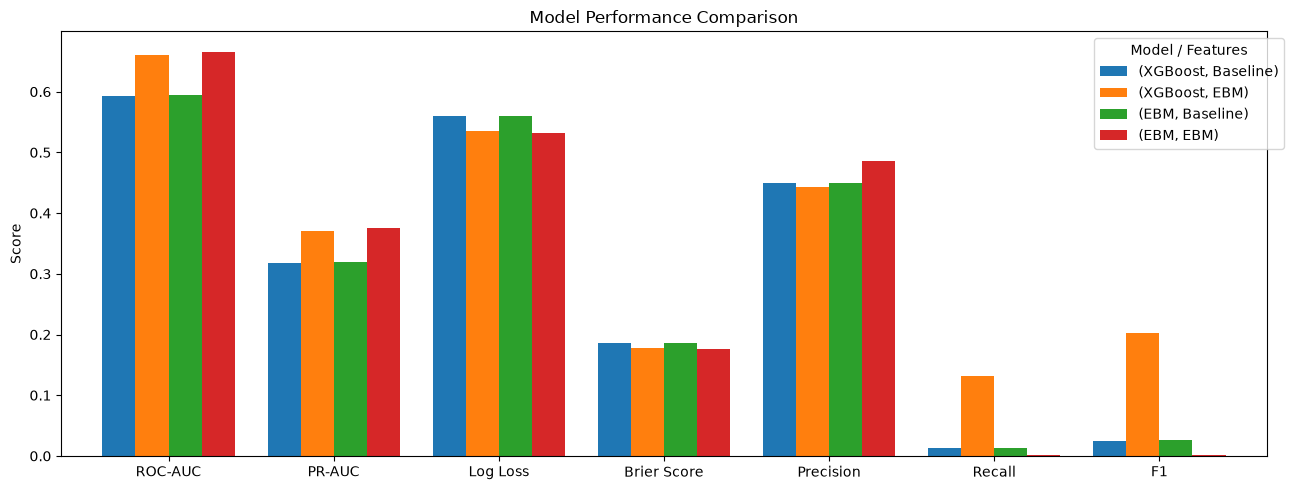

In [78]:
# Combine results
results_combined = pd.concat({
    "XGBoost": results_df_baseline_XGB,
    "EBM": results_df_baseline_EBM
})

# Plot metrics
ax = results_combined.T.plot(
    kind="bar",
    figsize=(13, 5),
    rot=0,
    width=0.8
)

ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.legend(title="Model / Features", bbox_to_anchor=(1.02, 1))
plt.tight_layout()

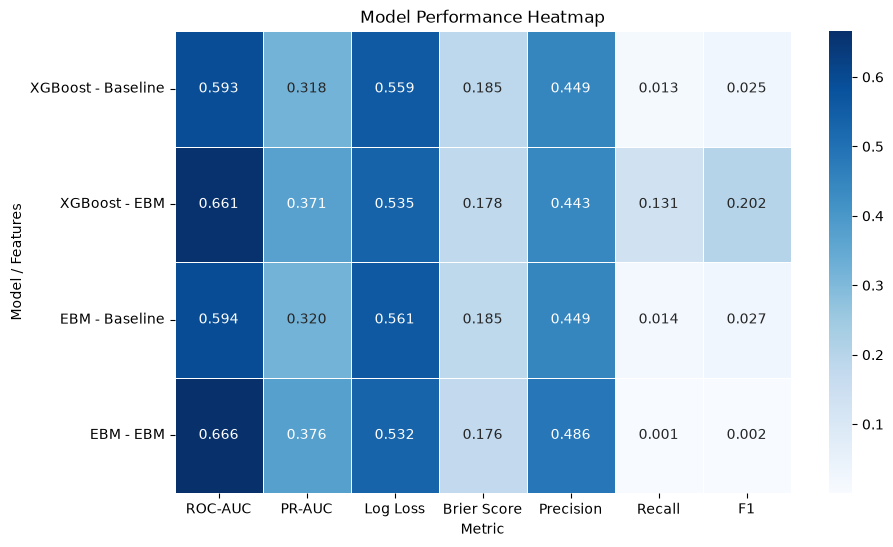

In [96]:
plt.figure(figsize=(14, 6))

ax = sns.heatmap(
    results_combined,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=0.5
)

ax.set_yticklabels(
    [f"{model} - {features}" for model, features in results_combined.index],
    rotation=0
)

plt.title("Model Performance Heatmap")
plt.xlabel("Metric")
plt.ylabel("Model / Features")

plt.yticks(rotation=0)
plt.subplots_adjust(left=0.35)

plt.show()